# Tahap 2 — Agregasi mingguan gerai × merek

Notebook ini membentuk kontrak data Tahap 2 dari transaksi yang telah bersih.
Keputusan D1 mempertahankan granularitas gerai × merek: mean fraksi minggu
tanpa penjualan harus sekitar 0.258 dan tidak boleh melebihi 0.30. Keputusan
D2 menerapkan resampling mingguan agar tiap deret memiliki kalender yang sama.

In [1]:
from __future__ import annotations
from pathlib import Path
import json
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
CFG = yaml.safe_load((ROOT / "config.yaml").read_text(encoding="utf-8"))
SEED = int(CFG["seed"])
np.random.seed(SEED)

def rp(*parts: str) -> Path:
    """Resolve a repo-relative path (parts are path fragments under the repo root)."""
    return ROOT.joinpath(*parts)

BRAND_COLORS = {"OPPO": "#0072B2", "Realme": "#D55E00", "Samsung": "#009E73",
                "Vivo": "#CC79A7", "Xiaomi": "#E69F00"}
ALGO_COLORS = {"SARIMAX": "#0072B2", "RF": "#D55E00", "LSTM": "#009E73"}
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (9, 4.5),
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 12})

Transaksi bersih Tahap 1 dimuat dari lokasi interim yang di-resolve relatif
terhadap akar repositori.

In [2]:
clean = pd.read_parquet(rp("data", "interim", "transactions_clean.parquet"))
clean.head()

,sales_no,created_at,paid_at,status,order_type,customer_name,product_name,variant_name,sku,category,...,service_charge,rounding,grand_total,payment_method,staff_name,printer_id,note,store,brand,week_start
0,1-1-000040,2022-01-02 10:51:35,2022-01-02 10:51:56.080,Paid,Offline,None,OPPO A17,Black,OPP-A17,Handphone,...,0,0,4398000,QRIS,Fajar H.,PRN-02,None,Toko_B,OPPO,2021-12-27
1,1-1-000034,2022-01-02 11:29:15,2022-01-02 11:29:49.029,Paid,Offline,None,realme C35,Green,RLM-C35,Handphone,...,0,0,2399000,E-Wallet,Dewi R.,PRN-02,None,Toko_A,Realme,2021-12-27
2,1-1-000004,2022-01-02 12:06:20,2022-01-02 12:08:33.983,Paid,Offline,None,OPPO A16,Silver,OPP-A16,Handphone,...,0,0,2099000,Cicilan 0%,Citra W.,PRN-01,None,Toko_B,OPPO,2021-12-27
3,1-1-000031,2022-01-02 14:28:02,2022-01-02 14:29:11.557,Paid,Offline,None,Xiaomi Redmi Note 11,Glowing Black,XIA-RN11,Handphone,...,0,0,2799000,Cicilan 0%,Fajar H.,None,None,Toko_A,Xiaomi,2021-12-27
4,1-1-000056,2022-01-02 16:07:05,2022-01-02 16:07:12.453,Paid,Offline,None,Samsung Galaxy A14,Glowing Black,SAM-A14,Handphone,...,0,0,2599000,QRIS,Dewi R.,PRN-02,None,Toko_A,Samsung,2021-12-27


Fungsi berikut membangun grid penuh semua gerai, merek, dan Senin dalam rentang
data. Minggu tanpa penjualan diisi nol, bukan dianggap nilai hilang.

In [3]:
import logging

logger = logging.getLogger(__name__)

N_WEEKS_EXPECTED = 184  # grid penuh (§1.2, diverifikasi pada data riil)
MAX_ZERO_WEEK_FRAC = 0.30  # ambang D1


def zero_week_fraction(weekly: pd.DataFrame) -> pd.Series:
    """Fraksi minggu dengan units==0 per deret (store, brand), urut menurun."""
    return (
        weekly.assign(is_zero=weekly["units"].eq(0))
        .groupby(["store", "brand"])["is_zero"]
        .mean()
        .sort_values(ascending=False)
    )

In [4]:
def aggregate_weekly(
    clean: pd.DataFrame,
    out_path: str | Path | None = None,
    max_zero_week_frac: float = MAX_ZERO_WEEK_FRAC,
) -> pd.DataFrame:
    """Agregasi transaksi bersih -> deret mingguan gerai x merek pada grid penuh."""
    g = (
        clean.groupby(["store", "brand", "week_start"], as_index=False)["qty"]
        .sum()
        .rename(columns={"qty": "units"})
    )

    stores = sorted(clean["store"].unique())
    brands = sorted(clean["brand"].unique())
    weeks = pd.date_range(
        clean["week_start"].min(), clean["week_start"].max(), freq="W-MON"
    )
    full_index = pd.MultiIndex.from_product(
        [stores, brands, weeks], names=["store", "brand", "week_start"]
    )
    weekly = (
        g.set_index(["store", "brand", "week_start"])
        .reindex(full_index, fill_value=0)
        .reset_index()
        .sort_values(["store", "brand", "week_start"])
        .reset_index(drop=True)
    )
    weekly["units"] = weekly["units"].astype(int)

    n_series = weekly.groupby(["store", "brand"]).ngroups
    zero_frac = zero_week_fraction(weekly)
    mean_zero_frac = float(zero_frac.mean())

    stats = {
        "n_rows": len(weekly),
        "n_series": int(n_series),
        "n_weeks": len(weeks),
        "units": int(weekly["units"].sum()),
        "mean_zero_week_frac": mean_zero_frac,
        "zero_week_frac_by_series": {
            f"{s}|{b}": round(float(v), 4) for (s, b), v in zero_frac.items()
        },
    }
    weekly.attrs["stats"] = stats

    logger.info(
        "aggregate: %d baris (%d deret x %d minggu), Σunits=%d, mean_zero_frac=%.4f",
        stats["n_rows"], stats["n_series"], stats["n_weeks"], stats["units"], mean_zero_frac,
    )
    logger.info("5 deret dengan fraksi minggu-nol tertinggi:")
    for (s, b), v in zero_frac.head(5).items():
        logger.info("    %s x %s: %.3f", s, b, v)

    assert weekly["units"].notna().all(), "Ada NaN pada units setelah reindex/fill."
    assert (weekly["units"] >= 0).all(), "units negatif — tak seharusnya."
    assert len(weeks) == N_WEEKS_EXPECTED, (
        f"Grid minggu = {len(weeks)}, diharapkan {N_WEEKS_EXPECTED} (§1.2)."
    )
    assert mean_zero_frac <= max_zero_week_frac, (
        f"mean fraksi minggu-nol = {mean_zero_frac:.4f} > {max_zero_week_frac} "
        "-> keputusan D1 (gerai x merek) tidak valid pada data ini; STOP & lapor."
    )

    if out_path is not None:
        out_path = Path(out_path)
        out_path.parent.mkdir(parents=True, exist_ok=True)
        weekly.to_parquet(out_path, index=False)
        logger.info("Tersimpan: %s", out_path)

    return weekly

Agregasi disimpan tanpa kondisi sebagai artefak deterministik yang dikonsumsi
notebook tahap berikutnya.

In [5]:
weekly = aggregate_weekly(
    clean,
    rp("data", "interim", "weekly_store_brand.parquet"),
)
weekly.attrs["stats"]

{'n_rows': 3680,
 'n_series': 20,
 'n_weeks': 184,
 'units': 6907,
 'mean_zero_week_frac': 0.257608695652174,
 'zero_week_frac_by_series': {'Toko_D|Vivo': 0.4783,
  'Toko_C|Vivo': 0.4402,
  'Toko_D|Realme': 0.4076,
  'Toko_D|Samsung': 0.3696,
  'Toko_B|Vivo': 0.3587,
  'Toko_C|Realme': 0.3478,
  'Toko_C|Samsung': 0.2989,
  'Toko_B|Realme': 0.288,
  'Toko_C|Xiaomi': 0.2772,
  'Toko_D|OPPO': 0.2663,
  'Toko_A|Realme': 0.2337,
  'Toko_A|Vivo': 0.2228,
  'Toko_D|Xiaomi': 0.212,
  'Toko_C|OPPO': 0.1848,
  'Toko_B|Xiaomi': 0.1739,
  'Toko_A|Samsung': 0.1522,
  'Toko_B|Samsung': 0.1522,
  'Toko_B|OPPO': 0.1196,
  'Toko_A|OPPO': 0.0978,
  'Toko_A|Xiaomi': 0.0707}}

Grafik berikut memperlihatkan fraksi minggu tanpa penjualan untuk setiap deret.
Warna batang mengikuti identitas merek agar konsisten di seluruh notebook.

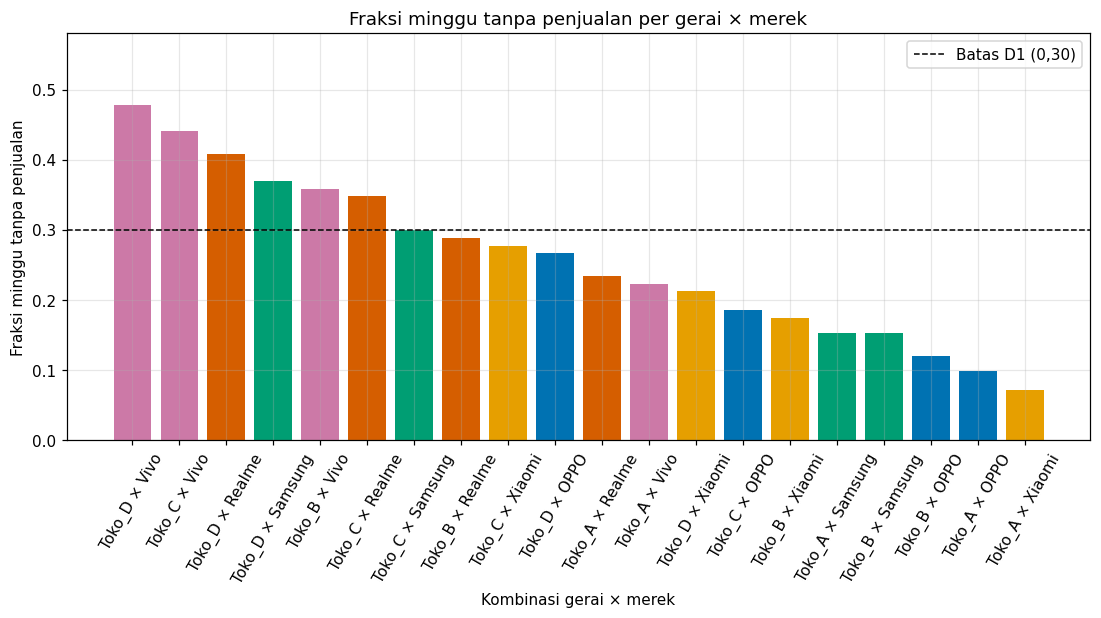

In [6]:
zero_frac = zero_week_fraction(weekly)
labels = [f"{store} × {brand}" for store, brand in zero_frac.index]
colors = [BRAND_COLORS[brand] for _, brand in zero_frac.index]
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.bar(labels, zero_frac.values, color=colors)
ax.axhline(MAX_ZERO_WEEK_FRAC, color="black", linestyle="--", linewidth=1, label="Batas D1 (0,30)")
ax.set_title("Fraksi minggu tanpa penjualan per gerai × merek")
ax.set_xlabel("Kombinasi gerai × merek")
ax.set_ylabel("Fraksi minggu tanpa penjualan")
ax.set_ylim(0, 0.58)
ax.tick_params(axis="x", rotation=60)
ax.legend()
plt.show()

In [7]:
st = weekly.attrs["stats"]
assert st["n_rows"] == 3680, st
assert st["n_series"] == 20 and st["n_weeks"] == 184
assert st["units"] == 6907
assert st["mean_zero_week_frac"] <= 0.30, "D1 dilanggar"
assert abs(st["mean_zero_week_frac"] - 0.258) < 0.01, st["mean_zero_week_frac"]
assert weekly["units"].notna().all() and (weekly["units"] >= 0).all()
print(f"✅ Tahap 2: 20×184=3680, Σ=6907, mean_zero_frac={st['mean_zero_week_frac']:.3f} ≤0.30 (D1)")

✅ Tahap 2: 20×184=3680, Σ=6907, mean_zero_frac=0.258 ≤0.30 (D1)
